#4 Homework, Machine Learning Zoomcamp 2026, Evaluation metrics for classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

#4.1 Data preparation


In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!wget $data -O course_lead_scoring_2026.csv

--2026-10-19 20:20:16--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 278746 (272K) [text/plain]
Saving to: ‘course_lead_scoring_2026.csv’

course_lead_scoring 100%[===================>] 272.21K  --.-KB/s    in 0.004s  

2026-10-19 20:20:16 (62.2 MB/s) - ‘course_lead_scoring_2026.csv’ saved [278746/278746]



In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [10]:
categorical=list(df.dtypes[df.dtypes == 'string'].index)
numerical= []
for col in df.columns:
    if col not in categorical + ['converted']:
        numerical.append(col)

categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [11]:
df[categorical]=df[categorical].fillna('NA')
df[numerical]=df[numerical].fillna(0)

In [12]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [13]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [14]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

#Q1 ROC AUC feature importance

In [17]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc_inv = roc_auc_score(y_train, -df_train[c])
        print(f'{c}: {auc_inv:.4f}')
    else:
        print(f'{c}: {auc:.4f}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


#Q2 Model AUC

In [ ]:
features = categorical + numerical

#Hot encoding
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

#Model training
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)


y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
auc, round(auc, 3) 

(0.7318222288173319, 0.732)

#Q3 Precision and Recall

In [20]:
thresholds = np.arange(0.0, 1.0, 0.01)

scores = []
for t in thresholds:
    y_hat = (y_pred >= t).astype(int)
    precision = precision_score(y_val, y_hat, zero_division=0)
    recall = recall_score(y_val, y_hat, zero_division=0)
    scores.append((t, precision, recall))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_scores.head()



,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


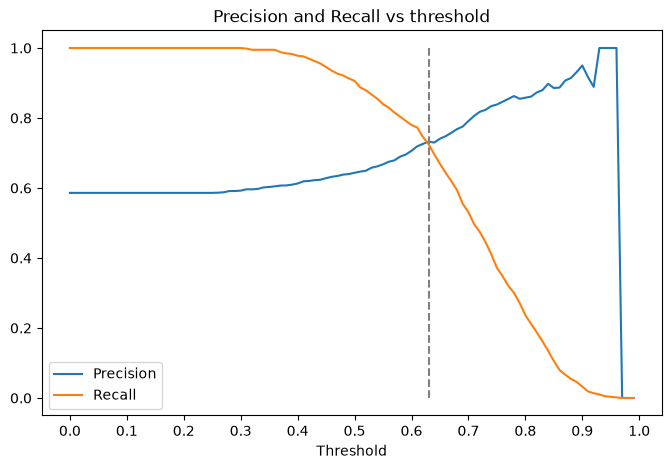

In [21]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.vlines(0.63, 0, 1, colors='grey', linestyles='dashed')
plt.xticks(np.arange(0, 1.01, 0.1))
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision and Recall vs threshold')
plt.show()

In [22]:
d = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
d['diff'] = (d.precision - d.recall).abs()
d.sort_values(['diff', 'threshold']).head()

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


#Q4 F1 score


In [23]:
df_scores['f1'] = (2 * df_scores.precision * df_scores.recall
                   / (df_scores.precision + df_scores.recall))
df_scores = df_scores.fillna(0)

df_scores.sort_values('f1', ascending=False).head()

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


In [24]:
df_scores.loc[df_scores.f1.idxmax(), 'threshold']

np.float64(0.41000000000000003)

#Q5 5-Fold CV standard deviation

In [25]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    m.fit(X_tr, y_tr)
    return dv, m


def predict(df_x, dv, m):
    X = dv.transform(df_x[features].to_dict(orient='records'))
    return m.predict_proba(X)[:, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv, m = train(df_tr, df_tr.converted.values)
    scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, m)))

print([round(s, 4) for s in scores])

np.mean(scores), np.std(scores), round(np.std(scores), 3)

[0.7306, 0.7296, 0.7363, 0.7412, 0.7209]


(np.float64(0.7317269710972524),
 np.float64(0.006853233151022138),
 np.float64(0.007))

#Q6 Best C or Hyper parame

In [26]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    s = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, m = train(df_tr, df_tr.converted.values, C)
        s.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, m)))

    print(f'C={C:<10} mean={round(np.mean(s), 3)}  std={round(np.std(s), 3)}')

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01
C=1          mean=0.732  std=0.007
